# 4. Lab data, Raman spectra and measurement noise

A real plant does not see the model states. It has online probes, lab assays that come back later, and possibly a
Raman probe. This notebook shows all three, and how to add realistic sensor and assay errors.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

from penicillium import MeasurementNoise, Sensor, Simulator

result = Simulator().run(seed=1)
df = result.to_pandas()

## Lab results

Penicillin, biomass, PAA, nitrogen and viscosity are assayed every 12 h (and at 1 h and at the end). Each result
appears in the row of the time it is **reported**, and holds the value at the time the broth was **sampled**
(`offline_delay_steps` samples earlier, 48 min by default). Rows between reports are NaN.

In [2]:
lab = df[["P_offline", "X_offline", "PAA_offline", "NH3_offline", "Viscosity_offline"]].dropna()
lab.head(8).round(2)

,P_offline,X_offline,PAA_offline,NH3_offline,Viscosity_offline
time_h,,,,,
1.0,0.00,0.48,1314.48,1730.31,4.08
12.0,0.00,3.20,1414.13,1850.74,10.93
24.0,0.00,9.37,1103.66,1849.18,22.00
36.0,2.00,13.10,533.75,1741.38,35.55
48.0,4.81,16.43,440.05,1753.47,49.70
60.0,7.49,18.38,712.45,1724.30,41.36
72.0,9.89,19.38,896.02,1646.83,26.13
84.0,12.62,21.03,913.35,1584.46,27.39


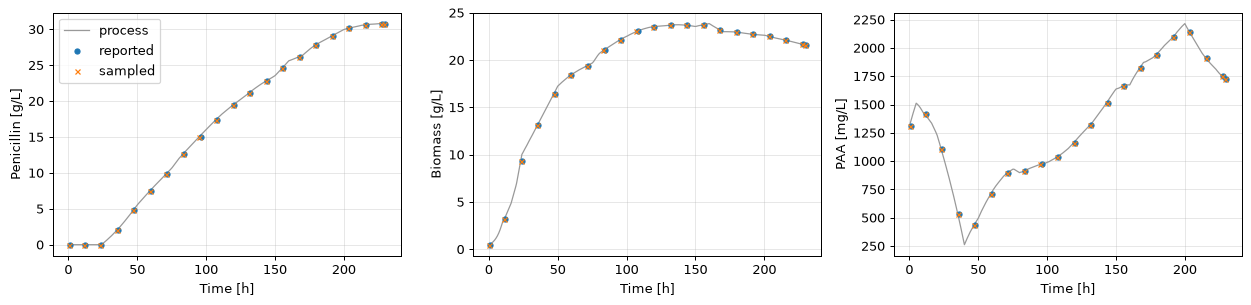

In [3]:
delay_h = result.config.offline_delay_steps * 0.2
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, (true, assay, label) in zip(
    axes,
    [("P", "P_offline", "Penicillin [g/L]"), ("X", "X_offline", "Biomass [g/L]"), ("PAA", "PAA_offline", "PAA [mg/L]")],
):
    ax.plot(result.time, result[true], color="0.6", lw=1, label="process")
    ax.plot(lab.index, lab[assay], "o", ms=4, label="reported")
    ax.plot(lab.index - delay_h, lab[assay], "x", ms=4, label="sampled")
    ax.set(xlabel="Time [h]", ylabel=label)
axes[0].legend()
fig.tight_layout()

## Raman spectra

From 2 h on, a simulated Raman probe records one spectrum per sample: 2200 intensities from 201 to 2400 cm⁻¹.
`result.raman` is the NumPy array (wavenumbers descending, as in IndPenSim); `result.raman_to_pandas()` gives a
DataFrame with ascending wavenumbers.

(1150, 2200)


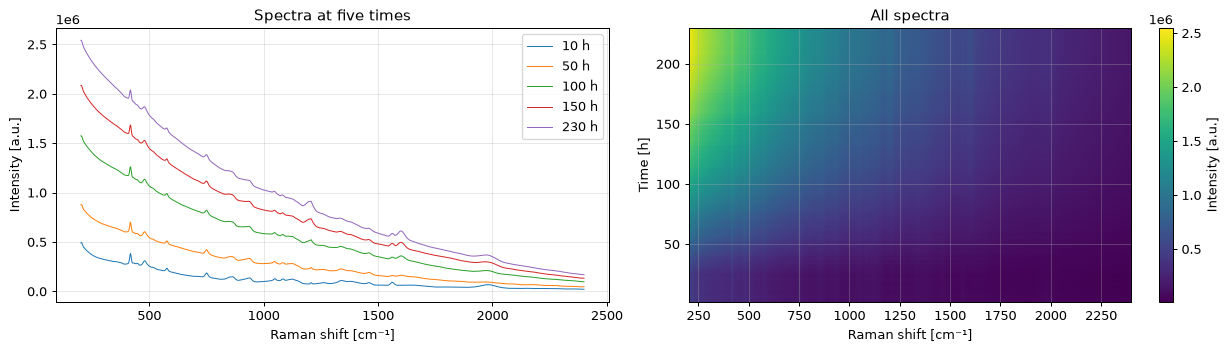

In [4]:
spectra = result.raman_to_pandas()
print(spectra.shape)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
for t in (10, 50, 100, 150, 230):
    ax1.plot(spectra.columns, spectra.loc[t], lw=0.8, label=f"{t} h")
ax1.set(xlabel="Raman shift [cm⁻¹]", ylabel="Intensity [a.u.]", title="Spectra at five times")
ax1.legend()
im = ax2.imshow(
    spectra.iloc[10:].to_numpy(),
    aspect="auto",
    origin="lower",
    cmap="viridis",
    extent=[spectra.columns[0], spectra.columns[-1], spectra.index[10], spectra.index[-1]],
)
ax2.set(xlabel="Raman shift [cm⁻¹]", ylabel="Time [h]", title="All spectra")
fig.colorbar(im, ax=ax2, label="Intensity [a.u.]")
fig.tight_layout()

The spectra change with penicillin, biomass, PAA, substrate and viscosity, plus a drifting fluorescence baseline and
noise. [Tutorial 6](06_raman_soft_sensor.ipynb) builds a soft sensor from them.

The same spectra as a 3D waterfall, one every 5 h:

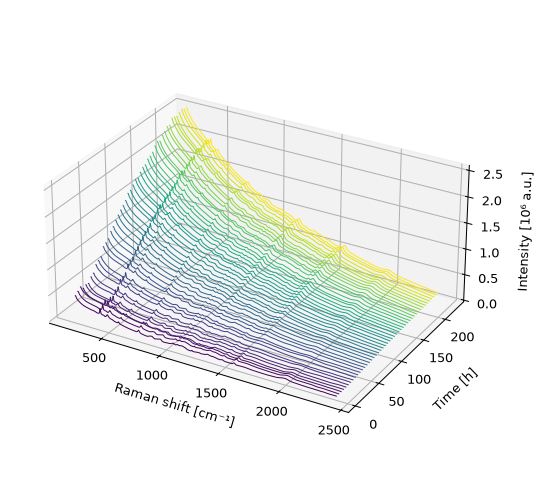

In [5]:
shown = spectra.iloc[10::25]  # spectra start after sample 10; every 25th sample = 5 h
wavenumber = spectra.columns.to_numpy(dtype=float)

fig = plt.figure(figsize=(12, 7))
ax = fig.add_subplot(projection="3d")
colors = plt.cm.viridis(np.linspace(0, 1, len(shown)))
for color, (time_h, spectrum) in zip(colors, shown.iterrows()):
    ax.plot(wavenumber, np.full_like(wavenumber, time_h), spectrum.to_numpy() / 1e6, color=color, lw=0.8)
ax.set_xlabel("Raman shift [cm⁻¹]", labelpad=10)
ax.set_ylabel("Time [h]", labelpad=10)
ax.set_zlabel("Intensity [10⁶ a.u.]", labelpad=8)
ax.view_init(elev=28, azim=-60)
ax.set_box_aspect((2.2, 1.6, 1), zoom=0.9)

## Measurement noise

The simulator's channels are exact. `MeasurementNoise` turns them into what instruments would read: white noise,
a calibration offset drawn per batch, drift, resolution, and assay error on the lab results. The exact values stay
available in `noisy.truth`.

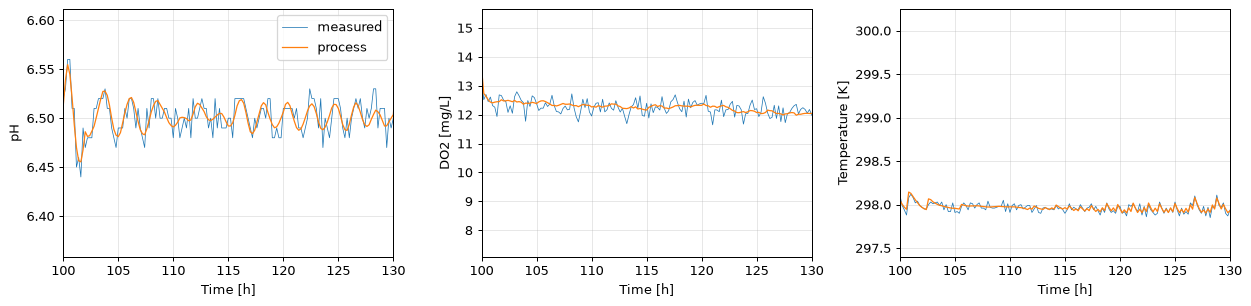

In [6]:
noisy = MeasurementNoise.typical().apply(result)  # seeded by the batch seed; pass seed=... to change it

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, (name, label) in zip(axes, [("pH", "pH"), ("DO2", "DO2 [mg/L]"), ("T", "Temperature [K]")]):
    ax.plot(noisy.time, noisy[name], lw=0.6, label="measured")
    ax.plot(noisy.time, noisy.truth[name], lw=1, label="process")
    ax.set(xlabel="Time [h]", ylabel=label)
    ax.set_xlim(100, 130)
axes[0].legend()
fig.tight_layout()

In [7]:
compare = pd.DataFrame(
    {"P lab (measured)": noisy["P_offline"], "P lab (exact)": noisy.truth["P_offline"]}, index=noisy.time
).dropna()
compare = compare[compare["P lab (exact)"] > 0.5]  # from the first lab result with penicillin in it
compare["error %"] = 100 * (compare.iloc[:, 0] / compare.iloc[:, 1] - 1)
compare.round(2).head(8)

,P lab (measured),P lab (exact),error %
36.0,2.03,2.00,1.62
48.0,4.75,4.81,-1.17
60.0,7.44,7.49,-0.73
72.0,10.05,9.89,1.57
84.0,12.53,12.62,-0.72
96.0,14.73,15.07,-2.22
108.0,16.92,17.42,-2.89
120.0,20.04,19.41,3.27


Each sensor can be changed or switched off, and the whole noise level scaled:

In [8]:
custom = MeasurementNoise.typical().with_(
    pH=Sensor(sd=0.02, resolution=0.01),  # a noisier electrode
    Fc=None,  # cooling water flow exact
)
noisier = MeasurementNoise.typical().scaled(2.0)
for name, model in (("typical", MeasurementNoise.typical()), ("custom", custom), ("2x typical", noisier)):
    r = model.apply(result)
    print(f"{name:11s} pH residual sd = {np.nanstd(r['pH'] - r.truth['pH']):.4f}")

typical     pH residual sd = 0.0104
custom      pH residual sd = 0.0203
2x typical  pH residual sd = 0.0203


## Everything in one file

For tools that want a single table per batch: one row per 12-minute sample, with the process channels, the lab
results (empty between reports) and the 2200 Raman intensities.

In [9]:
import tempfile
from pathlib import Path

from penicillium import CHANNELS

process = [n for n in CHANNELS if not n.endswith("_offline")]
lab_names = [n for n in CHANNELS if n.endswith("_offline")]
table = pd.concat(
    [
        df[process].rename(columns=lambda n: f"{n} [{CHANNELS[n][1]}]"),
        df[lab_names].rename(columns=lambda n: f"lab_{n.removesuffix('_offline')} [{CHANNELS[n][1]}]"),
        spectra.rename(columns=lambda w: f"raman_{int(w)}"),
    ],
    axis=1,
)
path = Path(tempfile.mkdtemp()) / "batch_seed1_all.csv"
table.to_csv(path, float_format="%.6g")
print(f"{table.shape[0]} rows x {table.shape[1]} columns, {path.stat().st_size / 1e6:.0f} MB")

1150 rows x 2255 columns, 21 MB


Details in [Lab data and Raman spectra](../measurements.md). The notebook `notebooks/measurement_noise.ipynb` in
the repository checks the noise model statistically, channel by channel.

**Next:** [Campaigns and fault detection](05_campaigns_and_fault_detection.ipynb).